# 1.  The Heat Equation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from stepper import time_stepper
from stepper import relative_error

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "mathtext.fontset": "dejavusans",
})
plt.style.use('tableau-colorblind10')
# Set the global font size
plt.rcParams['font.size'] = 16

# Part 1

In [26]:
def exact(x, y, t):
    return np.cos(10*t) * np.sin(x) * np.sin(y)

def f(x, y, t):
    return (2*np.cos(10*t) - 10*np.sin(10*t)) * np.sin(x) * np.sin(y)

N = 64

stepper = time_stepper(f, N, 0, 2*np.pi, exact)
x,y = stepper.getGrid()

t_init = 0
t_max = 2*np.pi
dt = (t_max-t_init) / 30

# returns a flattened vector(without boundary conditions)
u_numerical = stepper.time_step(dt, t_init, t_max, "rk45")

# reconstruct
U = np.zeros((N, N))
U[1:-1, 1:-1] = u_numerical.reshape(N-2, N-2)

In [27]:
fig_plotly = go.Figure()

fig_plotly.add_trace(
    go.Surface(
        x=x, y=y, z=U,
        colorscale="Plasma",
        colorbar=dict(title="u(x, y)"),
        opacity=0.85,
        name="Numerical solution",
        showscale=True,
    ),
)

fig_plotly.update_layout(
    title="RK45 solution to forced heat equation on 64x64 grid",
    width=1100, height=650,
    margin=dict(b=90),
    legend=dict(orientation="h", x=0.5, xanchor="center", y=-0.12, yanchor="top"),
    scene=dict(
        xaxis_title="x",
        yaxis_title="y",
        zaxis_title="u(x, y)",
        aspectmode="manual",
        aspectratio=dict(x=1, y=1, z=0.55),
        camera=dict(eye=dict(x=1.5, y=-1.5, z=0.8)),
    ),
)
fig_plotly.show()

# Problem 1

In [6]:
t_init = 0
t_max = 2 * np.pi

stepper64 = time_stepper(f, 64, 0, 2*np.pi, exact)

x64, y64 = stepper64.getGrid()
X64, Y64 = np.meshgrid(x64, y64)
U_exact_64 = exact(X64, Y64, t_max)[1:-1, 1:-1]
u_exact_64 = U_exact_64.flatten()

stepper128 = time_stepper(f, 128, 0, 2*np.pi, exact)

x128, y128 = stepper128.getGrid()
X128, Y128 = np.meshgrid(x128, y128)
U_exact_128 = exact(X128, Y128, t_max)[1:-1, 1:-1]
u_exact_128 = U_exact_128.flatten()

# Explicit methods
M_explicit = [3000, 6000, 12000, 24000, 48000]

# Implicit methods
M_implicit = [40, 80, 160, 320, 640]

dt_explicit = [t_max / M for M in M_explicit]
dt_explicit_64 = dt_explicit[:4]
dt_explicit_128 = dt_explicit[2:]

dt_implicit = [t_max / M for M in M_implicit]

explicit_methods = ["forward_euler", "rk2"]
implicit_methods = ["backward_euler", "crank_nicolson", "bdf2"]

all_methods = explicit_methods + implicit_methods

numerical_solutions_64 = {}
numerical_solutions_128 = {}
rel_error_64 = {}
rel_error_128 = {}


In [7]:
for method in explicit_methods:
    rel_error_64[method] = []
    rel_error_128[method] = []
    for dt in dt_explicit_64:
        u_num_64 = stepper64.time_step(dt, t_init, t_max, method)
        # numerical_solutions_64[method] = u_num_64
        rel_error_64[method].append(relative_error(u_num_64, u_exact_64))

    for dt in dt_explicit_128:
        u_num_128 = stepper128.time_step(dt, t_init, t_max, method)
        # numerical_solutions_128[method] = u_num_128
        rel_error_128[method].append(relative_error(u_num_128, u_exact_128))

    print(f"{method} complete")

forward_euler complete
rk2 complete


In [8]:
for method in implicit_methods:
    rel_error_64[method] = []
    rel_error_128[method] = []
    for dt in dt_implicit:
        u_num_64 = stepper64.time_step(dt, t_init, t_max, method)
        # numerical_solutions_64[method] = u_num_64
        rel_error_64[method].append(relative_error(u_num_64, u_exact_64))

        u_num_128 = stepper128.time_step(dt, t_init, t_max, method)
        # numerical_solutions_128[method] = u_num_128
        rel_error_128[method].append(relative_error(u_num_128, u_exact_128))
    print(f"{method} complete")


backward_euler complete
crank_nicolson complete
bdf2 complete


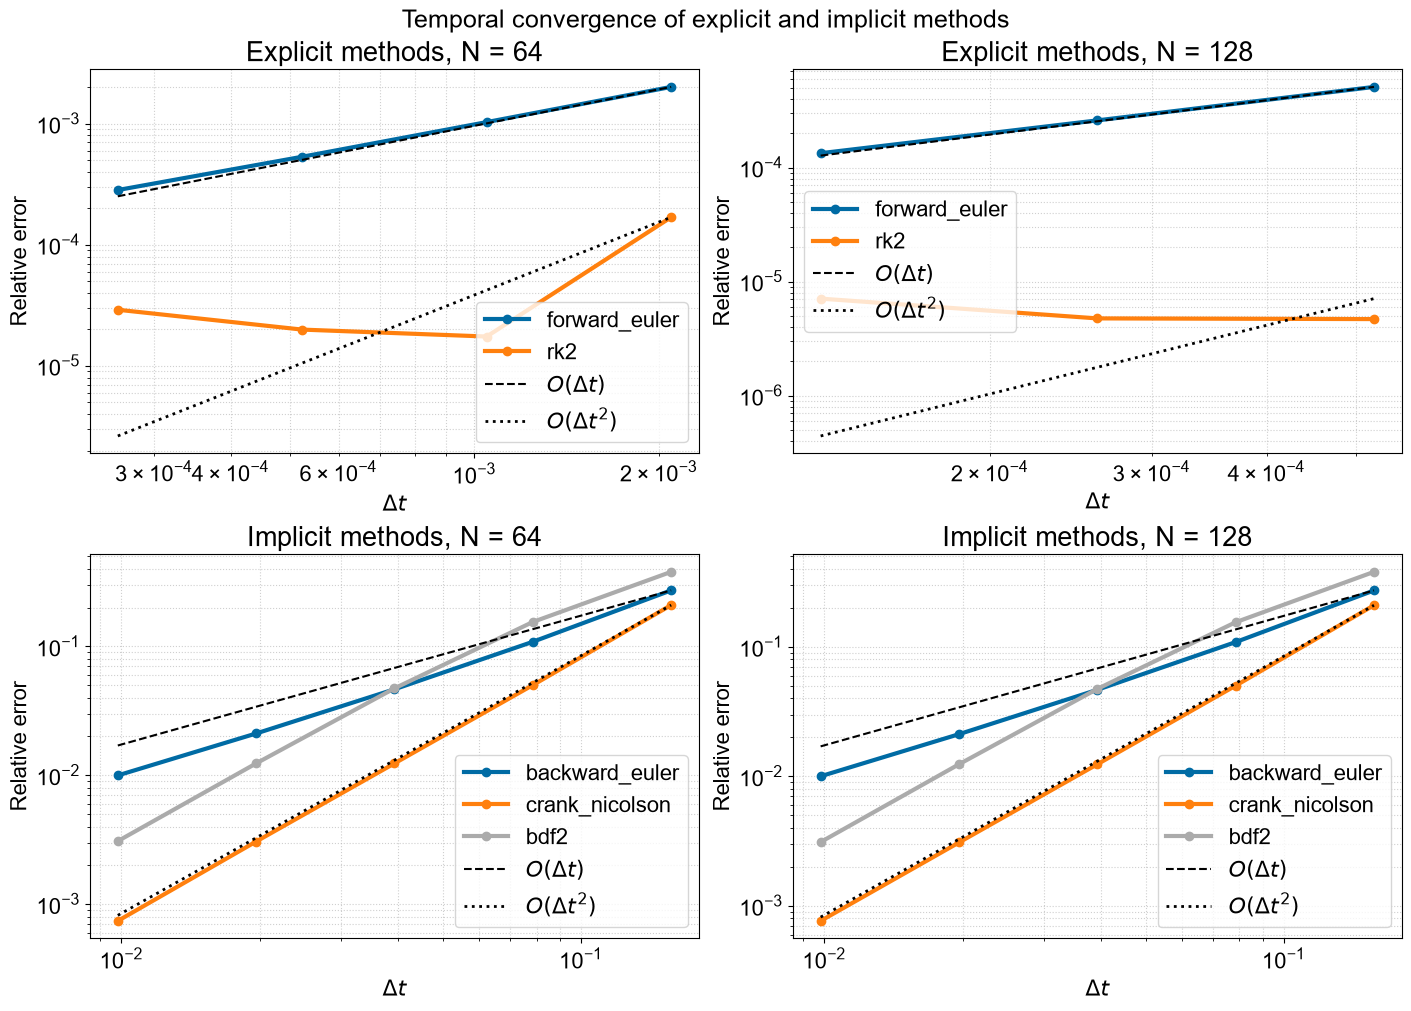

In [28]:
# Temporal convergence plots: rows are method families and columns are grid resolutions.
plot_specs = [
    ("Explicit methods, N = 64", explicit_methods, dt_explicit_64, rel_error_64),
    ("Explicit methods, N = 128", explicit_methods, dt_explicit_128, rel_error_128),
    ("Implicit methods, N = 64", implicit_methods, dt_implicit, rel_error_64),
    ("Implicit methods, N = 128", implicit_methods, dt_implicit, rel_error_128),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)

for ax, (title, methods, dts, errors) in zip(axes.flat, plot_specs):
    dts = np.asarray(dts)
    if 'forward_euler' in methods:
        max_error_1 = max(errors['forward_euler'])
        max_error_2 = max(errors['rk2'])
    else:
        max_error_1 = max(errors['backward_euler'])
        max_error_2 = max(errors['crank_nicolson'])
    dt_ref = np.linspace(dts.min(), dts.max(), 200)

    for method in methods:
        ax.loglog(dts, errors[method], "o-", linewidth=3, markersize=6, label=method)

    # Both reference curves meet at the largest timestep for easy comparison.
    ax.loglog(dt_ref, max_error_1 * (dt_ref / dts.max()), "k--", label=r"$O(\Delta t)$")
    ax.loglog(dt_ref, max_error_2 * (dt_ref / dts.max())**2, "k:", linewidth=2, label=r"$O(\Delta t^2)$")
    ax.set_title(title)
    ax.set_xlabel(r"$\Delta t$")
    ax.set_ylabel("Relative error")
    ax.grid(True, which="both", linestyle=":", alpha=0.6)
    ax.legend()

fig.suptitle("Temporal convergence of explicit and implicit methods", fontsize=18)
plt.show()


# Problem 2

In [10]:
def largest_admissible_dt(stepper, u_exact, method, error_threshold, t_init=0, t_max=2*np.pi, max_steps=200000):
    """Return the largest timestep (smallest integer step count) meeting an error target.

    The search assumes the error decreases as the timestep is refined near the
    threshold.  Every trial uses dt = (t_max - t_init) / M, so the solution
    always reaches t_max exactly after M steps.
    """
    if error_threshold <= 0:
        raise ValueError("error_threshold must be positive.")

    duration = t_max - t_init
    if duration <= 0:
        raise ValueError("t_max must be greater than t_init.")

    trials = {}

    def error_for_steps(n_steps):
        if n_steps not in trials:
            dt = duration / n_steps
            try:
                u_numerical = stepper.time_step(dt, t_init, t_max, method)
                error = relative_error(u_numerical, u_exact)
            except (FloatingPointError, OverflowError, RuntimeError):
                error = np.inf
            trials[n_steps] = error if np.isfinite(error) else np.inf
        return trials[n_steps]

    # Find a failing/passing bracket by successively halving dt.
    lower_steps, upper_steps = 3, 3
    while error_for_steps(upper_steps) > error_threshold:
        lower_steps = upper_steps
        upper_steps *= 2
        if upper_steps > max_steps:
            raise RuntimeError(f"No admissible dt found with at most {max_steps} steps.")

    # Integer bisection finds the smallest passing M, hence the largest dt.
    while upper_steps - lower_steps > 1:
        middle_steps = (lower_steps + upper_steps) // 2
        if error_for_steps(middle_steps) <= error_threshold:
            upper_steps = middle_steps
        else:
            lower_steps = middle_steps

    n_steps = upper_steps
    return {
        "method": method,
        "error_threshold": error_threshold,
        "n_steps": n_steps,
        "dt": duration / n_steps,
        "relative_error": error_for_steps(n_steps),
        "function_evaluations": len(trials),
    }

largest_dts = {}


In [11]:
# Find each seperately
largest_dts['fe1_64'] = largest_admissible_dt(stepper64, u_exact_64, "forward_euler", 5e-2)
largest_dts['fe2_64'] = largest_admissible_dt(stepper64, u_exact_64, "forward_euler", 1e-3)

largest_dts['fe1_128'] = largest_admissible_dt(stepper128, u_exact_128, "forward_euler", 5e-2)
largest_dts['fe2_128'] = largest_admissible_dt(stepper128, u_exact_128, "forward_euler", 1e-3)

c:\Users\jacks\OneDrive - Colorado School of Mines\Desktop\NumericalPDE\.venv\Lib\site-packages\numpy\linalg\_linalg.py:2767: RuntimeWarning: overflow encountered in dot
  sqnorm = x.dot(x)
c:\Users\jacks\OneDrive - Colorado School of Mines\Desktop\NumericalPDE\HW3\stepper.py:59: RuntimeWarning: invalid value encountered in add
  u = u + dt * (self.L @ u + self.F(t))


In [12]:
# Find each separately
largest_dts['rk21_64'] = largest_admissible_dt(stepper64, u_exact_64, "rk2", 5e-2)
largest_dts['rk22_64'] = largest_admissible_dt(stepper64, u_exact_64, "rk2", 1e-3)

largest_dts['rk21_128'] = largest_admissible_dt(stepper128, u_exact_128, "rk2", 5e-2)
largest_dts['rk22_128'] = largest_admissible_dt(stepper128, u_exact_128, "rk2", 1e-3)


c:\Users\jacks\OneDrive - Colorado School of Mines\Desktop\NumericalPDE\HW3\stepper.py:99: RuntimeWarning: invalid value encountered in add
  u_half = u + (dt / 2) * (self.L @ u + self.F(t))


In [13]:
# Find each separately
largest_dts['be1_64'] = largest_admissible_dt(stepper64, u_exact_64, "backward_euler", 5e-2)
largest_dts['be2_64'] = largest_admissible_dt(stepper64, u_exact_64, "backward_euler", 1e-3)

largest_dts['be1_128'] = largest_admissible_dt(stepper128, u_exact_128, "backward_euler", 5e-2)
largest_dts['be2_128'] = largest_admissible_dt(stepper128, u_exact_128, "backward_euler", 1e-3)


In [14]:
# Find each separately
largest_dts['cn1_64'] = largest_admissible_dt(stepper64, u_exact_64, "crank_nicolson", 5e-2)
largest_dts['cn2_64'] = largest_admissible_dt(stepper64, u_exact_64, "crank_nicolson", 1e-3)

largest_dts['cn1_128'] = largest_admissible_dt(stepper128, u_exact_128, "crank_nicolson", 5e-2)
largest_dts['cn2_128'] = largest_admissible_dt(stepper128, u_exact_128, "crank_nicolson", 1e-3)


In [15]:
# Find each separately
largest_dts['bdf21_64'] = largest_admissible_dt(stepper64, u_exact_64, "bdf2", 5e-2)
largest_dts['bdf22_64'] = largest_admissible_dt(stepper64, u_exact_64, "bdf2", 1e-3)

largest_dts['bdf21_128'] = largest_admissible_dt(stepper128, u_exact_128, "bdf2", 5e-2)
largest_dts['bdf22_128'] = largest_admissible_dt(stepper128, u_exact_128, "bdf2", 1e-3)


In [16]:
def cost(largest_dts):
    for key, res in largest_dts.items():
        N = 64**2
        if '128' in key:
            N = 128**2
        cost = 0
        matrix_ops = 0
        if res['method'] in implicit_methods:
            cost += N ** (3/2)
            matrix_ops = N * np.log(N)
        else:
            matrix_ops = 5 * N
            if 'rk2' in res['method']:
                matrix_ops *= 2

        cost += res['n_steps'] * matrix_ops
        res['cost'] = cost

cost(largest_dts)
largest_dts['bdf22_128']

{'method': 'bdf2',
 'error_threshold': 0.001,
 'n_steps': 1125,
 'dt': 0.005585053606381854,
 'relative_error': np.float64(0.000998251764624015),
 'function_evaluations': 20,
 'cost': np.float64(180962395.64913276)}

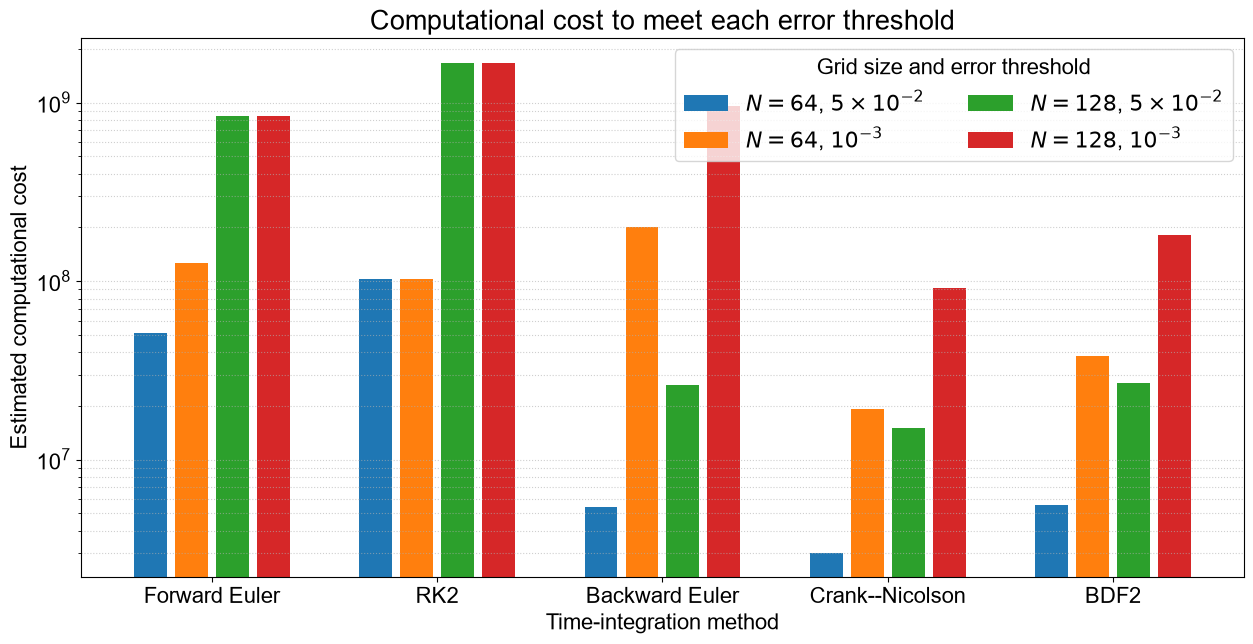

In [17]:
# Group the four cost results for each method, with a gap between methods.
cost_keys = {
    "Forward Euler": ["fe1_64", "fe2_64", "fe1_128", "fe2_128"],
    "RK2": ["rk21_64", "rk22_64", "rk21_128", "rk22_128"],
    "Backward Euler": ["be1_64", "be2_64", "be1_128", "be2_128"],
    "Crank--Nicolson": ["cn1_64", "cn2_64", "cn1_128", "cn2_128"],
    "BDF2": ["bdf21_64", "bdf22_64", "bdf21_128", "bdf22_128"],
}
bar_labels = [r"$N=64$, $5\times10^{-2}$", r"$N=64$, $10^{-3}$",
              r"$N=128$, $5\times10^{-2}$", r"$N=128$, $10^{-3}$"]
colors = plt.cm.tab10.colors[:4]

# Recompute costs if this cell is run before the cost-calculation cell.
if any("cost" not in largest_dts[key] for keys in cost_keys.values() for key in keys):
    cost(largest_dts)

fig, ax = plt.subplots(figsize=(15, 7))
group_width, group_gap = 4, 1.5
group_starts = np.arange(len(cost_keys)) * (group_width + group_gap)

for bar_index, (label, color) in enumerate(zip(bar_labels, colors)):
    values = [largest_dts[keys[bar_index]]["cost"] for keys in cost_keys.values()]
    ax.bar(group_starts + bar_index, values, width=0.8, color=color, label=label)

ax.set_xticks(group_starts + (group_width - 1) / 2)
ax.set_xticklabels(cost_keys.keys())
ax.set_yscale("log")
ax.set_xlabel("Time-integration method")
ax.set_ylabel("Estimated computational cost")
ax.set_title("Computational cost to meet each error threshold")
ax.grid(axis="y", which="both", linestyle=":", alpha=0.6)
ax.legend(title="Grid size and error threshold", ncols=2)
plt.show()


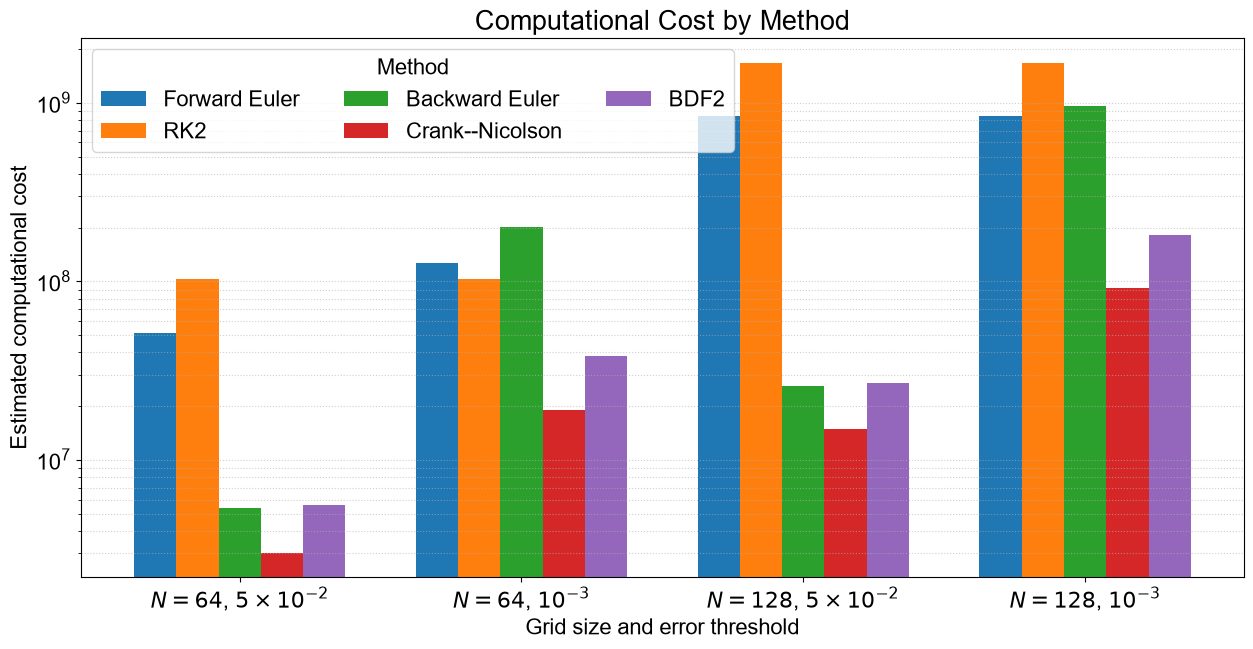

In [29]:
# Four groups: one for each grid size and error threshold.
# Colors distinguish the five time-integration methods.
cost_keys = {
    "Forward Euler": ["fe1_64", "fe2_64", "fe1_128", "fe2_128"],
    "RK2": ["rk21_64", "rk22_64", "rk21_128", "rk22_128"],
    "Backward Euler": ["be1_64", "be2_64", "be1_128", "be2_128"],
    "Crank--Nicolson": ["cn1_64", "cn2_64", "cn1_128", "cn2_128"],
    "BDF2": ["bdf21_64", "bdf22_64", "bdf21_128", "bdf22_128"],
}

group_labels = [
    r"$N=64$, $5\times10^{-2}$",
    r"$N=64$, $10^{-3}$",
    r"$N=128$, $5\times10^{-2}$",
    r"$N=128$, $10^{-3}$",
]

if any("cost" not in largest_dts[key] for keys in cost_keys.values() for key in keys):
    cost(largest_dts)

fig, ax = plt.subplots(figsize=(15, 7))

method_names = list(cost_keys)
colors = plt.cm.tab10.colors[:len(method_names)]
group_positions = np.arange(len(group_labels))
bar_width = 0.15
offsets = (np.arange(len(method_names)) - (len(method_names) - 1) / 2) * bar_width

for method_index, (method, keys) in enumerate(cost_keys.items()):
    values = [largest_dts[key]["cost"] for key in keys]
    ax.bar(
        group_positions + offsets[method_index],
        values,
        width=bar_width,
        color=colors[method_index],
        label=method,
    )

ax.set_xticks(group_positions)
ax.set_xticklabels(group_labels)
ax.set_yscale("log")
ax.set_xlabel("Grid size and error threshold")
ax.set_ylabel("Estimated computational cost")
ax.set_title("Computational Cost by Method")
ax.grid(axis="y", which="both", linestyle=":", alpha=0.6)
ax.legend(title="Method", ncols=3)

plt.show()